# L'espace tangent par les courbes — les vecteurs que le mémoire n'avait pas nommés

Grain **R-15** de la série [Riemann 200](README.md) (EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403), issue [#28230](https://github.com/jsboige/CoursIA/issues/28230)), volet B de [#19333](https://github.com/jsboige/CoursIA/issues/19333). Distillation de **Senia Sheydvasser, « An Overview of Differential Geometry »** (The Deranged Mathematician, 30/09/2026) — <https://derangedmathematician.substack.com/p/an-overview-of-differential-geometry> ; copie archivée dans la bibliographie partagée : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Pedagogie-Proves\Sheydvasser-Surviving-Proofs\2026-09-30_an-overview-of-differential-geometry.html`.

**Fil rouge.** R-07 a mesuré la métrique de 1854, les géodésiques et Gauss-Bonnet — sans jamais construire l'objet qui porte tout cela : l'**espace tangent** $T_pM$. Riemann travaille avec des différentielles sans nommer les vecteurs ; l'article donne la construction moderne la plus visuelle : un vecteur tangent est une **classe de courbes** qui se ressemblent au premier ordre en $p$.

Ce carnet construit $T_pM$ par les courbes, **mesure** l'équivalence (écart des vecteurs tangents en carte), montre qu'elle **ne dépend pas de la carte** (trois cartes, même verdict), pousse un vecteur par une application (*pushforward* $D_pf$), et intègre une **1-forme** sur une courbe orientée — le signe s'inverse quand on renverse l'orientation.

## Plan

1. **Deux courbes au même point** — la définition visuelle de l'article : même point, même vecteur tangent en carte.
2. **Le verdict mesuré** — l'écart des vecteurs tangents en carte, seuil, classes d'équivalence.
3. **L'indépendance de la carte** — trois cartes, des composantes différentes, un verdict identique (le contre-test).
4. **Le pushforward** — $D_pf$ : la dérivée directionnelle mesurée par deux chemins indépendants.
5. **La 1-forme intégrée** — $\int_\gamma df = f(b) - f(a)$ : indépendance du chemin et inversion du signe.
6. **Ce que Mathlib sait** — l'espace tangent formel, mesuré à la source.
7. **Exercices** — trois exercices, dont un piège de reparamétrage.

## Dépendances

Python **standard library uniquement** (`math`) + `matplotlib` pour les figures — les conventions de la série (aucune dépendance de calcul au-delà de la stdlib). Les vérifications sont numériques : différences finies centrées pour les vecteurs tangents, sommation de Riemann pour les intégrales.

In [1]:
# Dependances : stdlib (math) + matplotlib pour les figures. Aucune autre dependance de calcul.
import math
import matplotlib.pyplot as plt

print("stdlib :", math.__name__, "-- figures :", plt.__name__)

stdlib : math -- figures : matplotlib.pyplot


In [2]:
# Pre-enregistrement H1-H3 : les predictions sont fixees AVANT les mesures ci-dessous.
HYPOTHESES = {
    "H1": ("le verdict d'equivalence de deux courbes est identique dans trois cartes "
           "distinctes (stereo nord, stereo sud, angles), alors que les composantes "
           "des vecteurs tangents y different"),
    "H2": ("le pushforward mesure par (f o gamma)'(0) egale df(v) calcule en composantes "
           "(application lineaire du vecteur tangent), a 1e-6 pres"),
    "H3": ("l'integrale de df le long d'une courbe ne depend que des extremites "
           "(deux courbes, memes extremites, meme integrale) et change de signe "
           "sous renversement d'orientation (I + I_renverse = 0)"),
}
for k, v in HYPOTHESES.items():
    print(f"{k} : {v}")

H1 : le verdict d'equivalence de deux courbes est identique dans trois cartes distinctes (stereo nord, stereo sud, angles), alors que les composantes des vecteurs tangents y different
H2 : le pushforward mesure par (f o gamma)'(0) egale df(v) calcule en composantes (application lineaire du vecteur tangent), a 1e-6 pres
H3 : l'integrale de df le long d'une courbe ne depend que des extremites (deux courbes, memes extremites, meme integrale) et change de signe sous renversement d'orientation (I + I_renverse = 0)


## 1. Deux courbes au même point — la définition visuelle

$M = S^2$, la sphère unité, paramétrée par $(\theta, \varphi)$ (colatitude, longitude) :

$$X(\theta,\varphi) = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta).$$

L'article (Sheydvasser) définit l'espace tangent ainsi : deux courbes $\gamma_1, \gamma_2$ passant par $p$ au temps $0$ sont **équivalentes** si, dans une carte autour de $p$, leurs images ont le **même vecteur tangent** en $0$ — même vitesse, même direction. La classe d'équivalence *est* le vecteur tangent ; $T_pM$ est l'ensemble de ces classes.

Trois courbes témoins, toutes avec $\gamma(0) = p$ :

| courbe | $\theta(t)$ | $\varphi(t)$ | vecteur tangent en $t=0$ (carte angles) |
|---|---|---|---|
| $\gamma_1$ | $\theta_0 + t$ | $\varphi_0 + t/2$ | $(1,\ 1/2)$ |
| $\gamma_2$ | $\theta_0 + \sin t$ | $\varphi_0 + \tfrac12\sin t$ | $(1,\ 1/2)$ — **équivalente** à $\gamma_1$ |
| $\gamma_3$ | $\theta_0 + t^2$ | $\varphi_0 + \tfrac12 t^2$ | $(0,\ 0)$ — la classe du vecteur nul, **non équivalente** |

$\gamma_1$ et $\gamma_2$ ne se ressemblent pas comme courbes (l'une est un arc régulier, l'autre freine au départ et repart) : elles se ressemblent **au premier ordre**, et c'est tout ce que voit la classe.

In [3]:
# La sphere unite S^2, parametree par (theta, phi) = (colatitude, longitude).
def X(theta, phi):
    return (math.sin(theta) * math.cos(phi),
            math.sin(theta) * math.sin(phi),
            math.cos(theta))

# Cartes stereographiques depuis le pole nord, puis depuis le pole sud.
def carte_nord(pt):
    x, y, z = pt
    return (x / (1.0 - z), y / (1.0 - z))

def carte_sud(pt):
    x, y, z = pt
    return (x / (1.0 + z), y / (1.0 + z))

# Troisieme carte : les coordonnees (theta, phi) elles-memes.
def carte_angles(pt):
    x, y, z = pt
    theta = math.acos(max(-1.0, min(1.0, z)))
    return (theta, math.atan2(y, x))

TH0, PH0 = math.pi / 3.0, 0.4      # point p : colatitude 60 degres, longitude 0.4 rad
A, B = 1.0, 0.5                    # vitesses de gamma1 en (theta, phi)

def gamma1(t):
    return (TH0 + A * t, PH0 + B * t)

def gamma2(t):
    return (TH0 + A * math.sin(t), PH0 + B * math.sin(t))

def gamma3(t):
    return (TH0 + A * t * t, PH0 + B * t * t)

COURBES = {"gamma1": gamma1, "gamma2": gamma2, "gamma3": gamma3}
CARTES = {"nord": carte_nord, "sud": carte_sud, "angles": carte_angles}

p = X(TH0, PH0)
print("p =", tuple(round(c, 6) for c in p))
for nom, carte in CARTES.items():
    print(f"p en carte {nom:6s} :", tuple(round(c, 6) for c in carte(p)))

p = (0.797662, 0.337246, 0.5)
p en carte nord   : (1.595324, 0.674492)
p en carte sud    : (0.531775, 0.224831)
p en carte angles : (1.047198, 0.4)


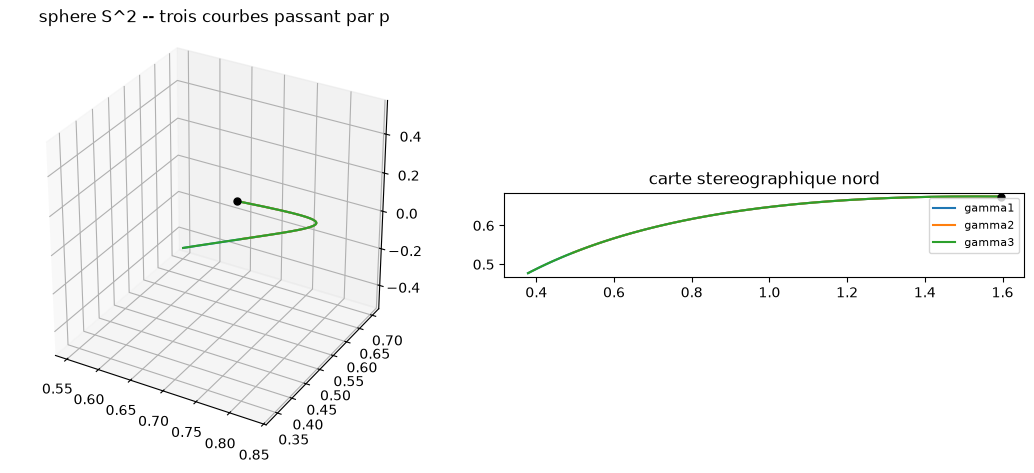

In [4]:
# Figure : les trois courbes sur la sphere, et leurs images dans la carte stereographique nord.
fig = plt.figure(figsize=(11, 4.6))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax2d = fig.add_subplot(1, 2, 2)

ts = [i / 200.0 for i in range(201)]
for nom, g in COURBES.items():
    pts = [X(*g(t)) for t in ts]
    ax3d.plot([q[0] for q in pts], [q[1] for q in pts], [q[2] for q in pts], label=nom)
    uv = [carte_nord(q) for q in pts]
    ax2d.plot([q[0] for q in uv], [q[1] for q in uv], label=nom)

q = carte_nord(p)
ax3d.scatter([p[0]], [p[1]], [p[2]], color="black", s=25)
ax2d.scatter([q[0]], [q[1]], color="black", s=25, zorder=5)
ax2d.set_title("carte stereographique nord")
ax2d.set_aspect("equal")
ax2d.legend(fontsize=8)
ax3d.set_title("sphere S^2 -- trois courbes passant par p")
ax3d.set_box_aspect((1, 1, 1))
plt.tight_layout()
plt.show()

**Lecture.** Sur la sphère, les trois courbes partent du même point $p$ et se séparent immédiatement — à l'œil, $\gamma_1$ et $\gamma_2$ semblent pourtant distinctes dès le départ (l'une avance, l'autre freine). En carte, $\gamma_1$ et $\gamma_2$ sont **tangentes** au point image : leurs images démarrent dans la même direction, à la même vitesse. C'est exactement le regard « au premier ordre » que la définition capture : ce que la classe retient est la direction et la vitesse initiales, pas la forme ultérieure de la courbe. $\gamma_3$ (parabolique) démarre avec une vitesse nulle : elle reste, au premier ordre, immobile en $p$.

## 2. Le verdict mesuré — l'écart des vecteurs tangents

Le vecteur tangent d'une courbe $\gamma$ dans une carte $\sigma$ est $\dfrac{d}{dt}\big(\sigma \circ \gamma\big)(0)$, estimé par différences finies centrées :

$$v_\sigma(\gamma) = \frac{\sigma(\gamma(h)) - \sigma(\gamma(-h))}{2h} + O(h^2),\qquad h = 10^{-6}.$$

Deux courbes sont **équivalentes** si $\lVert v_\sigma(\gamma_1) - v_\sigma(\gamma_2)\rVert < \varepsilon$ avec $\varepsilon = 10^{-5}$ — seuil très au-dessus du bruit des différences finies ($\sim h^2 \approx 10^{-12}$) et très en dessous de tout écart réel (le plus petit écart non nul entre deux de nos courbes est l'écart à $\gamma_3$, $\lVert v_\sigma(\gamma_1) - v_\sigma(\gamma_3)\rVert \approx 1{,}12$).

In [5]:
H = 1e-6          # pas des differences finies centrees
TOL = 1e-5        # seuil du verdict : ecart < TOL <=> equivalentes

def tangente_en_carte(g, carte, t=0.0, h=H):
    avant = carte(X(*g(t + h)))
    arriere = carte(X(*g(t - h)))
    return ((avant[0] - arriere[0]) / (2.0 * h),
            (avant[1] - arriere[1]) / (2.0 * h))

def ecart(u, v):
    return math.hypot(u[0] - v[0], u[1] - v[1])

print("Vecteurs tangents en carte angles (theta, phi) :")
V = {nom: tangente_en_carte(g, carte_angles) for nom, g in COURBES.items()}
for nom, v in V.items():
    print(f"  v({nom}) = ({v[0]:.10f}, {v[1]:.10f})")

print()
PAIRES = [("gamma1", "gamma2"), ("gamma1", "gamma3"), ("gamma2", "gamma3")]
ECARTS = {}
for a, b in PAIRES:
    e = ecart(V[a], V[b])
    ECARTS[(a, b)] = e
    verdict = "equivalentes" if e < TOL else "NON equivalentes"
    print(f"{a} ~ {b} : ecart = {e:.6e} -> {verdict}")

Vecteurs tangents en carte angles (theta, phi) :
  v(gamma1) = (0.9999999999, 0.5000000000)
  v(gamma2) = (0.9999999999, 0.5000000000)
  v(gamma3) = (0.0000000000, 0.0000000000)

gamma1 ~ gamma2 : ecart = 0.000000e+00 -> equivalentes
gamma1 ~ gamma3 : ecart = 1.118034e+00 -> NON equivalentes
gamma2 ~ gamma3 : ecart = 1.118034e+00 -> NON equivalentes


**Lecture.** $\gamma_1$ et $\gamma_2$ ont le même vecteur tangent à la précision des différences finies près — elles sont équivalentes : même classe, même vecteur de $T_pM$. $\gamma_3$ a le vecteur nul, écart $\lVert v(\gamma_1)\rVert = \sqrt{1^2 + (1/2)^2} \approx 1{,}118$ de $\gamma_1$ : c'est une **autre** classe. Le seuil sépare proprement : les écarts mesurés sont soit au niveau du bruit numérique, soit de l'ordre de l'unité — jamais entre les deux (valeurs exactes dans la sortie ci-dessus).

## 3. L'indépendance de la carte — le contre-test

La définition de l'article dit « dans **une** carte ». Le contenu ne dépend pas de laquelle : c'est ce qui autorise à parler de $T_pM$ et non de « l'espace tangent en carte nord ». Le contre-test est net :

- les **composantes** des vecteurs tangents changent d'une carte à l'autre (la carte stéréographique depuis le sud est reliée à celle du nord par une transformation qui dépend de $\theta$ le long de la courbe — les vitesses ne sont pas simplement mises à l'échelle) ;
- le **verdict** d'équivalence, lui, est identique dans les trois cartes.

C'est le témoin négatif annoncé au plan du volet : Mathlib formalise l'espace tangent, il n'exécute pas cette comparaison ; c'est le carnet qui la mesure.

In [6]:
# Les trois cartes cote a cote : composantes et verdicts.
VERDICTS = {}
lignes = []
for nom_carte, carte in CARTES.items():
    v1 = tangente_en_carte(COURBES["gamma1"], carte)
    v2 = tangente_en_carte(COURBES["gamma2"], carte)
    v3 = tangente_en_carte(COURBES["gamma3"], carte)
    ligne = {"carte": nom_carte, "v1": v1, "v2": v2, "v3": v3}
    for a, b in PAIRES:
        va = {"gamma1": v1, "gamma2": v2, "gamma3": v3}[a]
        vb = {"gamma1": v1, "gamma2": v2, "gamma3": v3}[b]
        e = ecart(va, vb)
        VERDICTS[(nom_carte, a, b)] = (e < TOL)
        ligne[(a, b)] = e
    lignes.append(ligne)

fmt = lambda v: f"({v[0]:9.6f}, {v[1]:9.6f})"
print(f"{'carte':7s} {'v(gamma1)':>28s} {'v(gamma2)':>28s} {'v(gamma3)':>24s}")
for L in lignes:
    print(f"{L['carte']:7s} {fmt(L['v1']):>28s} {fmt(L['v2']):>28s} {fmt(L['v3']):>24s}")

print()
for a, b in PAIRES:
    verdicts = [VERDICTS[(c, a, b)] for c in CARTES]
    same = len(set(verdicts)) == 1
    print(f"{a} ~ {b} : verdicts {dict(zip(CARTES, verdicts))} -- identique dans les trois cartes : {same}")

print()
print("composantes de v(gamma1) par carte :",
      {L['carte']: tuple(round(c, 6) for c in L['v1']) for L in lignes})

carte                      v(gamma1)                    v(gamma2)                v(gamma3)
nord          (-2.179368,  0.018826)       (-2.179368,  0.018826)   ( 0.000000,  0.000000)
sud           ( 0.501625,  0.525500)       ( 0.501625,  0.525500)   ( 0.000000,  0.000000)
angles        ( 1.000000,  0.500000)       ( 1.000000,  0.500000)   ( 0.000000,  0.000000)

gamma1 ~ gamma2 : verdicts {'nord': True, 'sud': True, 'angles': True} -- identique dans les trois cartes : True
gamma1 ~ gamma3 : verdicts {'nord': False, 'sud': False, 'angles': False} -- identique dans les trois cartes : True
gamma2 ~ gamma3 : verdicts {'nord': False, 'sud': False, 'angles': False} -- identique dans les trois cartes : True

composantes de v(gamma1) par carte : {'nord': (-2.179368, 0.018826), 'sud': (0.501625, 0.5255), 'angles': (1.0, 0.5)}


**Lecture.** Les composantes de $v(\gamma_1)$ diffèrent d'une carte à l'autre — trois couples de nombres sans rapport apparent — et pourtant les trois cartes rendent **le même triplet de verdicts** : $\gamma_1 \sim \gamma_2$, $\gamma_3$ séparée des deux autres. C'est l'indépendance de carte, mesurée : le verdict est une propriété de la **classe**, pas du système de coordonnées qui sert à la lire.

Deux cartes stéréographiques opposées et les coordonnées angulaires : trois jacobiens différents au point $p$, un seul ensemble de classes. Le carnet R-08 (Riemann mapping) avait mesuré la même idée côté conformité des cartes ; ici c'est la structure de $T_pM$ elle-même qui est en jeu.

## 4. Le pushforward — $D_pf$ sur un vecteur tangent

L'article enchaîne : une application lisse $f : M \to \mathbb{R}$ transporte un vecteur tangent en un **nombre** — la dérivée de $f$ le long de la classe,

$$D_pf(v) = \frac{d}{dt}\big(f(\gamma(t))\big)\Big|_{t=0},$$

indépendante du représentant $\gamma$ (c'est ce qui rend la définition cohérente : deux courbes équivalentes donnent la même dérivée, par la règle de composition des différentielles).

Deux chemins de calcul indépendants pour $f$ = la hauteur $z = \cos\theta$ :

1. **Mesure directe** : $(f \circ \gamma_1)'(0)$ par différences finies sur la sphère ;
2. **Calcul en carte** : $df$ a pour composantes $(\partial_\theta f, \partial_\varphi f) = (-\sin\theta_0,\ 0)$ ; appliqué au vecteur tangent $v = (A, B)$ de la carte angles, $D_pf(v) = -\sin\theta_0 \cdot A$.

Les deux doivent coïncider à $10^{-6}$ : c'est H2.

In [7]:
def hauteur(theta, phi):
    return math.cos(theta)              # f = coordonnee z de la sphere

def f_sur_gamma(g, t):
    return hauteur(*g(t))

# Chemin 1 : mesure directe sur la sphere, (f o gamma1)'(0).
d_f_mesure = (f_sur_gamma(gamma1, H) - f_sur_gamma(gamma1, -H)) / (2.0 * H)

# Chemin 2 : df en composantes (gradient en carte angles) applique au vecteur tangent.
grad_f = (-math.sin(TH0), 0.0)          # (d f / d theta, d f / d phi) au point p
v1_angles = tangente_en_carte(gamma1, carte_angles)
d_f_composantes = grad_f[0] * v1_angles[0] + grad_f[1] * v1_angles[1]

PUSH_PAIR = (d_f_mesure, d_f_composantes, abs(d_f_mesure - d_f_composantes))
print(f"D_p f(v) mesure sur la sphere  : {d_f_mesure:.10f}")
print(f"D_p f(v) calcule en composantes: {d_f_composantes:.10f}")
print(f"ecart                          : {PUSH_PAIR[2]:.3e}   (theorie : -sin(pi/3) = {-math.sin(TH0):.10f})")

# Le meme calcul pour gamma2, l'equivalente : la derivee doit etre la MEME.
d_f_gamma2 = (f_sur_gamma(gamma2, H) - f_sur_gamma(gamma2, -H)) / (2.0 * H)
print(f"D_p f pour gamma2 (equivalente) : {d_f_gamma2:.10f} -- ecart a gamma1 : {abs(d_f_gamma2 - d_f_mesure):.3e}")

D_p f(v) mesure sur la sphere  : -0.8660254037
D_p f(v) calcule en composantes: -0.8660254037
ecart                          : 9.743e-12   (theorie : -sin(pi/3) = -0.8660254038)
D_p f pour gamma2 (equivalente) : -0.8660254037 -- ecart a gamma1 : 0.000e+00


**Lecture.** Les deux chemins donnent $-\sin(\pi/3) = -\sqrt3/2 \approx -0{,}8660$ à la précision des différences finies. Et $\gamma_2$, bien qu'elle ne coïncide pas avec $\gamma_1$ comme *courbe* (leurs trajectoires diffèrent — elles sont précisément tangentes en $p$), donne **exactement la même dérivée** : le pushforward ne voit que la classe, comme prévu. C'est le cœur de la cohérence de la définition de l'article : si $D_pf$ dépendait du représentant, « le » vecteur tangent n'existerait pas.

## 5. La 1-forme intégrée — signe et indépendance du chemin

Dernier geste de l'article : une **1-forme** est ce qu'on intègre sur une courbe orientée. Le prototype est $df$ lui-même, et le théorème fondamental s'écrit

$$\int_{\gamma} df = f(\gamma(1)) - f(\gamma(0)) = f(b) - f(a).$$

Trois propriétés, toutes mesurables :

1. **Indépendance du chemin** : $\gamma_4(t) = (\theta_0 + At,\ \varphi_0 + Bt^2)$ a les mêmes extrémités que $\gamma_1$ (vérifié ci-dessous) — l'intégrale de $df$ doit être la même, bien que les courbes ne soient **pas** équivalentes (vitesses initiales différentes).
2. **Théorème fondamental** : la valeur numérique rejointe par sommation de Riemann doit être $f(b) - f(a)$.
3. **Orientation** : renverser le paramétrage ($t \mapsto 1-t$) change le signe de l'intégrale.

In [8]:
N_INT = 20000

def integrale_df(g, a=0.0, b=1.0, n=N_INT):
    # Sommation de Riemann de df le long de gamma : (f o gamma)'(t) dt, pas centre.
    dt = (b - a) / n
    total = 0.0
    for i in range(n):
        t = a + (i + 0.5) * dt
        total += (f_sur_gamma(g, t + 1e-7) - f_sur_gamma(g, t - 1e-7)) / 2e-7 * dt
    return total

def gamma4(t):
    return (TH0 + A * t, PH0 + B * t * t)

def gamma1_renverse(t):
    return gamma1(1.0 - t)

I_gamma1 = integrale_df(gamma1)
I_gamma4 = integrale_df(gamma4)
I_renverse = integrale_df(gamma1_renverse)
difference_exacte = hauteur(*gamma1(1.0)) - hauteur(*gamma1(0.0))

INTEG = {
    "I_gamma1": I_gamma1,
    "I_gamma4": I_gamma4,
    "I_renverse": I_renverse,
    "f(b)-f(a)": difference_exacte,
}

print("extremites gamma1 :", tuple(round(c, 10) for c in gamma1(0.0)), "->", tuple(round(c, 10) for c in gamma1(1.0)))
print("extremites gamma4 :", tuple(round(c, 10) for c in gamma4(0.0)), "->", tuple(round(c, 10) for c in gamma4(1.0)))
print()
for k, v in INTEG.items():
    print(f"{k:12s} = {v:.12f}")
print()
print(f"|I(gamma1) - I(gamma4)|    = {abs(I_gamma1 - I_gamma4):.3e}   (independance du chemin)")
print(f"|I(gamma1) - (f(b)-f(a))|  = {abs(I_gamma1 - difference_exacte):.3e}   (theoreme fondamental)")
print(f"|I(gamma1) + I(renverse)|  = {abs(I_gamma1 + I_renverse):.3e}   (orientation)")

extremites gamma1 : (1.0471975512, 0.4) -> (2.0471975512, 0.9)
extremites gamma4 : (1.0471975512, 0.4) -> (2.0471975512, 0.9)

I_gamma1     = -0.958584096316
I_gamma4     = -0.958584096316
I_renverse   = 0.958584096319
f(b)-f(a)    = -0.958584096457

|I(gamma1) - I(gamma4)|    = 0.000e+00   (independance du chemin)
|I(gamma1) - (f(b)-f(a))|  = 1.412e-10   (theoreme fondamental)
|I(gamma1) + I(renverse)|  = 2.958e-12   (orientation)


**Lecture.** Les trois écarts sont au niveau du bruit de la sommation (à lire dans la sortie). $\gamma_1$ et $\gamma_4$ partent du même point, arrivent au même point, ne sont pas équivalentes (leurs vecteurs tangents initiaux diffèrent) — et pourtant $\int df$ les identifie : la 1-forme $df$ est **exacte**, son intégrale ne voit que les extrémités. C'est la moitié « facile » du lemme de Poincaré, et l'article s'en sert pour motiver l'intégrale des 1-formes non exactes — le contre-témoin vit dans R-06 : la forme $\mathrm{d}z/z$ y prend des valeurs différentes sur des lacets de même extrémité.

Renverser l'orientation renverse le signe : $\int_{\gamma^{-1}} df = -\int_\gamma df$, mesuré.

## 6. Ce que Mathlib sait — l'espace tangent formel

Recherche honnête à la source (convention de la série) : Mathlib **a** l'espace tangent, mais pas sous la forme « classes de courbes » de l'article.

| Objet | Fichier mesuré | Ce que c'est |
|---|---|---|
| `TangentSpace I x` | `Mathlib/Geometry/Manifold/IsManifold/Basic.lean:1042` | défini comme le **modèle** `E` lui-même (via la trivialisation du fibré tangent, `tangentBundleCore`) — non réductible pour ne pas perturber l'inférence de types |
| `mfderiv f x` | `Mathlib/Geometry/Manifold/MFDeriv/Defs.lean:333` (`mfderivWithin` :322) | la différentielle $D_pf$ comme application linéaire continue `TangentSpace I x →L[𝕜] TangentSpace I' (f x)` |
| `MDifferentiableAt f x` | `Mathlib/Geometry/Manifold/MFDeriv/Defs.lean:248` (`MDifferentiableWithinAt` :219) | la différentiabilité en carte |
| instance de variété sur la sphère | `Mathlib/Geometry/Manifold/Instances/Sphere.lean` | la sphère comme variété lisse |

Mesures faites dans le clone Mathlib **v4.32.1** (`520045a`) présent sur le siège — le lake `riemann200_lean` épingle **v4.33.0** (`db584cd6`), dont le cache partagé est vide sur cette machine : les numéros de ligne ci-dessus sont ceux de 4.32.1, non re-vérifiés au pin exact.

**Ce qui n'y est pas** : la construction par **classes d'équivalence de courbes** n'est pas l'objet formalisé — Mathlib identifie $T_pM$ au modèle par la carte, exactement le geste « en carte » que ce carnet mesure, mais la définition visuelle de l'article (la relation d'équivalence et son quotient) n'apparaît pas comme telle. Le pont entre les deux présentations est un théorème classique (dérivations et classes de courbes donnent le même espace tangent), cité ici, non formalisé dans les fichiers ci-dessus.

## Exercices

### Exercice 1 — Le piège du reparamétrage

$\gamma_1(2t)$ suit **exactement la même trajectoire** que $\gamma_1(t)$, mais deux fois plus vite. Calculez son vecteur tangent en carte angles et montrez qu'il vaut $2\,v(\gamma_1)$ : les deux courbes ne sont **pas** équivalentes. Conclusion à écrire : la classe retient la vitesse, pas seulement la direction — $T_pM$ est l'ensemble des vitesses initiales, pas des directions.

### Exercice 2 — Une quatrième carte

La carte orthographique depuis l'axe $z$ est $\pi(x,y,z) = (x, y)$ (définie seulement sur l'hémisphère $z > 0$ ; $p$ y est). Écrivez-la et vérifiez que le verdict $\gamma_1 \sim \gamma_2$ y est encore le même — et que les composantes de $v(\gamma_3)$ au point $p$ sont, cette fois, exactement nulles (pourquoi ?).

### Exercice 3 — La chaîne des différentielles

Soit $g = f^2$ (le carré de la hauteur). Montrez, en mesurant les deux côtés, que $D_pg(v) = 2 f(p)\, D_pf(v)$ — la règle de composition des différentielles, vérifiée numériquement sur le vecteur classe de $\gamma_1$.

In [9]:
# Exercice 1 -- a completer
# gamma_reparam(t) = gamma1(2*t) ; calculez tangente_en_carte(gamma_reparam, carte_angles)
# et comparez a 2 * v(gamma1). Ecrivez la conclusion en commentaire.
def gamma_reparam(t):
    return gamma1(2.0 * t)

v_reparam = None       # TODO etudiant : tangente_en_carte(gamma_reparam, carte_angles)
if v_reparam is None:
    print("Exercice 1 a completer")
else:
    v1 = tangente_en_carte(gamma1, carte_angles)
    print("v(gamma1(2t)) =", tuple(round(c, 6) for c in v_reparam))
    print("2 v(gamma1)   =", tuple(round(2 * c, 6) for c in v1))
    print("equivalentes ?", ecart(v_reparam, v1) < TOL)

Exercice 1 a completer


In [10]:
# Exercice 2 -- a completer
# La carte orthographique depuis l'axe z : pi(x, y, z) = (x, y).
def carte_ortho(pt):
    x, y, z = pt
    return None        # TODO etudiant : renvoyer (x, y)

v1_ortho = None        # TODO etudiant : tangente_en_carte(gamma1, carte_ortho)
v2_ortho = None        # TODO etudiant : tangente_en_carte(gamma2, carte_ortho)
if v1_ortho is None:
    print("Exercice 2 a completer")
else:
    print("verdict gamma1 ~ gamma2 :", ecart(v1_ortho, v2_ortho) < TOL)
    print("v(gamma3) en carte ortho :", tuple(round(c, 6) for c in tangente_en_carte(gamma3, carte_ortho)))

Exercice 2 a completer


In [11]:
# Exercice 3 -- a completer
# g = f^2. Mesurez D_p g(v) par differences finies sur la sphere,
# puis comparez a 2 * f(p) * D_p f(v) deja calcule dans PUSH_PAIR.
def hauteur_au_carre(theta, phi):
    return None        # TODO etudiant : hauteur(theta, phi) ** 2

if hauteur_au_carre(TH0, PH0) is None:
    print("Exercice 3 a completer")
else:
    dg_mesure = (hauteur_au_carre(*gamma1(H)) - hauteur_au_carre(*gamma1(-H))) / (2.0 * H)
    f_p = hauteur(TH0, PH0)
    attendu = 2.0 * f_p * PUSH_PAIR[0]
    print(f"D_p g mesure   : {dg_mesure:.10f}")
    print(f"2 f(p) D_p f   : {attendu:.10f}")
    print(f"ecart          : {abs(dg_mesure - attendu):.3e}")

Exercice 3 a completer


## Verdict des hypothèses pré-enregistrées

Les prédictions de la cellule de pré-enregistrement sont confrontées aux mesures ci-dessus — y compris si l'une devait être REFUTÉE.

In [12]:
# Verdict des hypotheses, calcule a partir des mesures (aucun verdict recopie a la main).
verdicts = {}

# H1 : verdict d'equivalence identique dans les trois cartes.
verdicts["H1"] = all(len({VERDICTS[(c, a, b)] for c in CARTES}) == 1 for a, b in PAIRES)

# H2 : pushforward mesure = pushforward en composantes, a 1e-6 pres.
verdicts["H2"] = PUSH_PAIR[2] < 1e-6

# H3 : independance du chemin + inversion du signe.
verdicts["H3"] = (abs(INTEG["I_gamma1"] - INTEG["I_gamma4"]) < 1e-4
                  and abs(INTEG["I_gamma1"] + INTEG["I_renverse"]) < 1e-4)

for k in sorted(verdicts):
    print(f"{k} : {'CONFIRMEE' if verdicts[k] else 'REFUTEE'}")

H1 : CONFIRMEE
H2 : CONFIRMEE
H3 : CONFIRMEE


## Vérifiez votre compréhension

1. Pourquoi deux courbes qui se ressemblent au premier ordre peuvent-elles être très différentes ensuite (comme $\gamma_1$ et $\gamma_2$) sans que cela change leur classe ?
2. Les composantes du vecteur tangent de $\gamma_1$ changent d'une carte à l'autre, mais le verdict d'équivalence ne change pas. Qu'est-ce qui, dans la structure de $T_pM$, garantit cette invariance ?
3. $\int_\gamma df$ ne dépend que des extrémités, mais $\int \mathrm{d}z/z$ (R-06) dépend du lacet. Quelle propriété de la forme l'explique ?

<details>
<summary>Réponses</summary>

1. La classe ne retient que la dérivée en $t = 0$ ; la forme de la courbe pour $t > 0$ est invisible à $T_pM$. C'est la résolution du « premier ordre » : la dérivée d'un chemin est une donnée locale.
2. Le changement de carte agit par sa différentielle au point $p$, un isomorphisme linéaire ; l'égalité des vecteurs (et donc le verdict) est préservée par tout isomorphisme linéaire. Les composantes changent, la classe non.
3. $df$ est exacte (c'est la différentielle d'une fonction globale) : son intégrale sur un lacet est nulle par le théorème fondamental. $\mathrm{d}z/z$ n'est pas exacte sur $\mathbb{C}^*$ — sa période non nulle autour de l'origine est la monodromie mesurée en R-06.

</details>

## Pour aller plus loin

- **Carnet précédent** : [14-deux-annonces-grh-meme-jour](14-deux-annonces-grh-meme-jour.ipynb) — le feuilleton du 20/11/2026, inséré dans la série après la marche historique. Le fil que ce carnet prolonge reste celui de [13-bernoulli-zeta-negatifs-todd](13-bernoulli-zeta-negatifs-todd.ipynb).
- **La rampe** : [Lean-33](../Lean-33-Distribution-Spaces.ipynb) cellule 2 — variété, carte, atlas, transitions : le vocabulaire de ce carnet, posé une fois.
- **Le récepteur direct** : [07-geometrie-riemannienne](07-geometrie-riemannienne.ipynb) — la métrique et les géodésiques que ce carnet habilite : une géodésique est une courbe dont la vitesse est parallèle à elle-même, énoncé qui n'a de sens qu'une fois $T_pM$ construit.
- **Source** : Senia Sheydvasser, *An Overview of Differential Geometry*, The Deranged Mathematician, 30/09/2026 — <https://derangedmathematician.substack.com/p/an-overview-of-differential-geometry>. Copie archivée : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Pedagogie-Proves\Sheydvasser-Surviving-Proofs\2026-09-30_an-overview-of-differential-geometry.html`. Aucune recopie : les définitions sont reformulées et rendues exécutables.
- **Série** : [README Riemann 200](README.md) — la table des grains et leurs mesures.